<a href="https://colab.research.google.com/github/psh135230-design/BioAI_KU_2026/blob/main/%EB%B0%94%EC%9D%B4%EC%98%A4%EC%9D%B8%EA%B3%B5%EC%A7%80%EB%8A%A5_10_13(%ED%99%94).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
%pip install -q "pandas==2.2.3" "scanpy[leiden]==1.11.5"

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.1/2.1 MB 28.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 176.1/176.1 kB 11.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.7/5.7 MB 95.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.7/2.7 MB 70.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 79.1/79.1 kB 5.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 405.3/405.3 kB 23.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 230.5/230.5 kB 15.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 56.6 MB/s eta 0:00:00


In [2]:
import scanpy as sc
import pandas as pd

print("Scanpy:", sc.__version__)
print("Pandas:", pd.__version__)

Scanpy: 1.11.5
Pandas: 2.2.3


/tmp/ipykernel_2719/3927035035.py:4: FutureWarning: `__version__` is deprecated, use `importlib.metadata.version('scanpy')` instead
  print("Scanpy:", sc.__version__)


In [9]:
import os

file_path = "/content/GSE154763_MYE_count.h5"

if os.path.exists(file_path):
    try:
        # .h5ad 대신 10x Genomics .h5 파일을 읽는 함수를 사용합니다.
        adata = sc.read_10x_h5(file_path)
        print("Successfully loaded original dataset:")
        print(adata)
    except Exception as e:
        print(f"Could not load file: {e}")
else:
    print(f"File not found at {file_path}. Please re-upload or re-download the dataset.")

Successfully loaded original dataset:
AnnData object with n_obs × n_vars = 7619 × 15634
    var: 'gene_ids'


In [10]:
print("Data shape:", adata.shape)

print("\nCell metadata:")
print(adata.obs.columns.tolist())

print("\nGene metadata:")
print(adata.var.columns.tolist())

print("\nSaved embeddings:")
print(list(adata.obsm.keys()))

print("\nSaved analyses:")
print(list(adata.uns.keys()))

Data shape: (7619, 15634)

Cell metadata:
[]

Gene metadata:
['gene_ids']

Saved embeddings:
[]

Saved analyses:
[]


In [11]:
adata.var_names_make_unique()

# astype(bool)을 추가하여 Pandas BooleanArray 대신 NumPy boolean 배열로 변환하여 저장합니다.
adata.var['mt'] = adata.var_names.str.startswith('MT-').astype(bool)

sc.pp.calculate_qc_metrics(
    adata,
    qc_vars=['mt'],
    percent_top=None,
    inplace=True
)

print(adata.obs[
    ['n_genes_by_counts', 'total_counts', 'pct_counts_mt']
].describe())

       n_genes_by_counts  total_counts  pct_counts_mt
count        7619.000000   7619.000000    7619.000000
mean         1961.669904   6754.211839       3.882464
std           679.841537   4072.257968       1.150013
min           690.000000   2003.000000       0.000000
25%          1447.000000   3987.000000       3.162361
50%          1876.000000   5801.000000       3.732599
75%          2332.000000   8124.500000       4.405609
max          4943.000000  38618.000000       9.976019


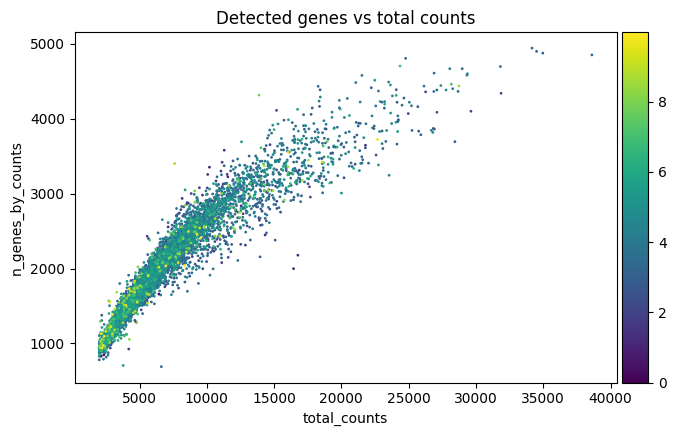

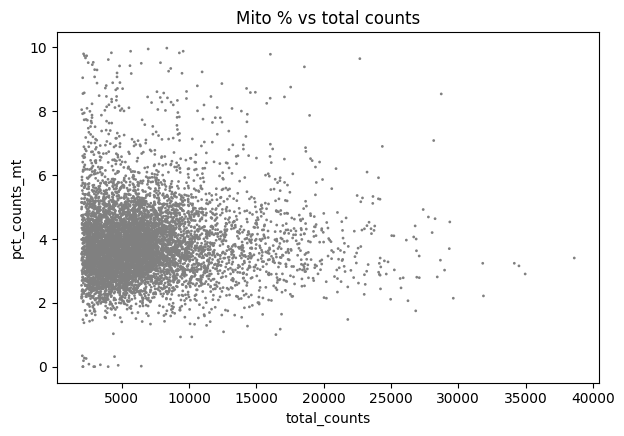

In [52]:
# 총 count vs 검출 유전자 수 (색 = 미토 비율)
sc.pl.scatter(adata, x='total_counts', y='n_genes_by_counts', color='pct_counts_mt',
              title='Detected genes vs total counts')

# 총 count vs 미토 비율
sc.pl.scatter(adata, x='total_counts', y='pct_counts_mt',
              title='Mito % vs total counts')

In [19]:
import numpy as np
from scipy import sparse

if sparse.issparse(adata.X):
    values = adata.X.data
else:
    values = np.asarray(adata.X).ravel()

print("Minimum:", values.min())
print("Maximum:", values.max())

# 모든 값이 정수인지 확인
print(
    "Integer counts:",
    np.allclose(values, np.round(values))
)

# 음수 존재 여부
print(
    "Non-negative:",
    np.all(values >= 0)
)

Minimum: 1.0
Maximum: 6140.0
Integer counts: True
Non-negative: True


In [20]:
# 원본 Count 데이터 보존
adata.layers["counts"] = adata.X.copy()

# 세포별 총 Count를 10,000으로 정규화
sc.pp.normalize_total(adata, target_sum=1e4)

# Log transformation
sc.pp.log1p(adata)

print(adata)

AnnData object with n_obs × n_vars = 7619 × 15634
    obs: 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'total_counts_mt', 'log1p_total_counts_mt', 'pct_counts_mt'
    var: 'gene_ids', 'mt', 'n_cells_by_counts', 'mean_counts', 'log1p_mean_counts', 'pct_dropout_by_counts', 'total_counts', 'log1p_total_counts'
    uns: 'log1p'
    layers: 'counts'


In [21]:
import numpy as np

# Raw count 데이터
raw_counts = adata.layers["counts"]

# 정규화 및 로그 변환된 데이터
normalized_data = adata.X

print("Raw counts shape:", raw_counts.shape)
print("Normalized data shape:", normalized_data.shape)

print("\nLog transformation 정보:")
print(adata.uns.get("log1p"))

print("\nRaw data:")
print(raw_counts[:5, :5].toarray())

print("\nNormalized & Log-transformed data:")
print(normalized_data[:5, :5].toarray())

Raw counts shape: (7619, 15634)
Normalized data shape: (7619, 15634)

Log transformation 정보:
{'base': None}

Raw data:
[[0. 1. 0. 0. 0.]
 [0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0.]
 [0. 1. 0. 0. 0.]
 [0. 1. 0. 0. 0.]]

Normalized & Log-transformed data:
[[0.         0.7152578  0.         0.         0.        ]
 [0.         0.         0.         0.         0.        ]
 [0.         0.         0.         0.         0.        ]
 [0.         1.11888233 0.         0.         0.        ]
 [0.         0.47150852 0.         0.         0.        ]]


Number of HVGs: 2000


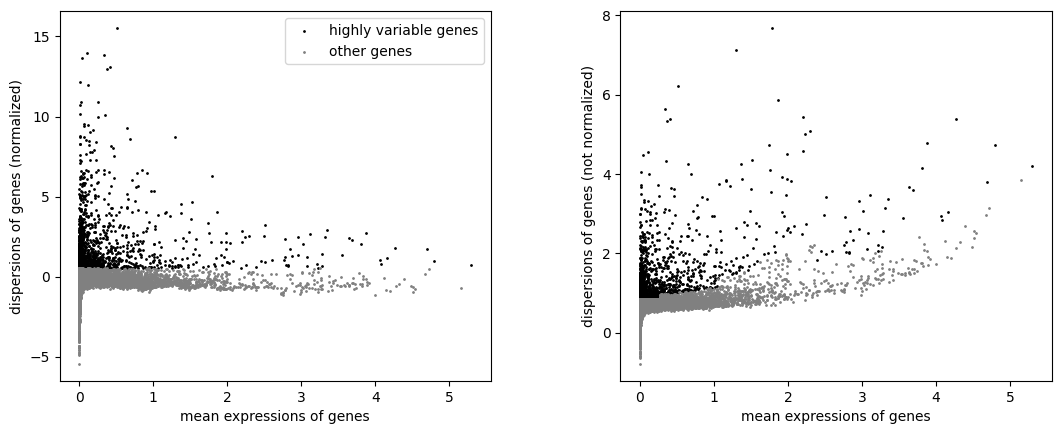

In [25]:
# HVG 2,000개 선정 (논문에서 STAR methods 분석할 때 HGV 2천 개 선정했다고 했음)
sc.pp.highly_variable_genes(
    adata,
    n_top_genes=2000,
    flavor='seurat'
)

# 선정된 HVG 개수 확인
print(
    "Number of HVGs:",
    adata.var['highly_variable'].sum()
)

# HVG 시각화
sc.pl.highly_variable_genes(adata)

In [27]:
from sklearn.metrics import adjusted_rand_score
sc.tl.pca(adata, n_comps=50)
for n in [10, 20, 30, 50]:
    sc.pp.neighbors(adata, n_pcs=n, key_added=f'nn{n}')
    sc.tl.leiden(adata, neighbors_key=f'nn{n}', key_added=f'leiden_{n}')
    print(n, adata.obs[f'leiden_{n}'].nunique(), '개 클러스터')
print('30 vs 50 일치도(ARI):', adjusted_rand_score(adata.obs['leiden_30'], adata.obs['leiden_50']))

/tmp/ipykernel_2719/1144379712.py:5: FutureWarning: In the future, the default backend for leiden will be igraph instead of leidenalg.

 To achieve the future defaults please pass: flavor="igraph" and n_iterations=2.  directed must also be False to work with igraph's implementation.
  sc.tl.leiden(adata, neighbors_key=f'nn{n}', key_added=f'leiden_{n}')


10 19 개 클러스터
20 17 개 클러스터
30 18 개 클러스터
50 18 개 클러스터
30 vs 50 일치도(ARI): 0.8201597352021124


PCA shape: (7619, 30)


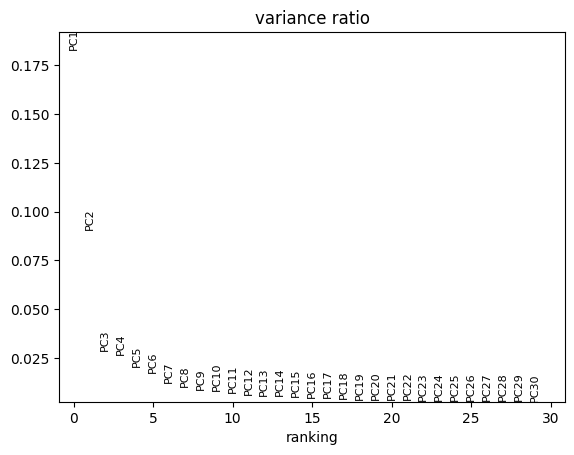

,주성분 (PC),설명 분산 비율 (%),누적 설명 분산 비율 (%)
0,PC1,18.28,18.28
1,PC2,9.05,27.33
2,PC3,2.86,30.19
3,PC4,2.68,32.87
4,PC5,2.04,34.91


In [30]:
# HVG 2,000개를 이용한 PCA
sc.tl.pca(
    adata,
    n_comps=30,
    mask_var='highly_variable',
    svd_solver='arpack'
)

# PCA 결과 확인
print("PCA shape:", adata.obsm['X_pca'].shape)


# 설명 분산 비율 시각화
sc.pl.pca_variance_ratio(
    adata,
    n_pcs=30,
    log=False
)

variance_ratio = adata.uns["pca"]["variance_ratio"][:5]
pcs = [f"PC{i+1}" for i in range(len(variance_ratio))]
explained_pct = variance_ratio * 100
cumulative_pct = np.cumsum(explained_pct)

pca_summary_df = pd.DataFrame(
    {
        "주성분 (PC)": pcs,
        "설명 분산 비율 (%)": np.round(explained_pct, 2),
        "누적 설명 분산 비율 (%)": np.round(cumulative_pct, 2),
    }
)

# 표 출력
pd.set_option("display.max_rows", 30)
display(pca_summary_df)

In [33]:
sc.pp.neighbors(
    adata,
    n_neighbors=15,
    n_pcs=30
)

sc.tl.umap(
    adata,
    random_state=0
)

sc.tl.leiden(
    adata,
    resolution=0.6,
    key_added='leiden',
    random_state=0
)

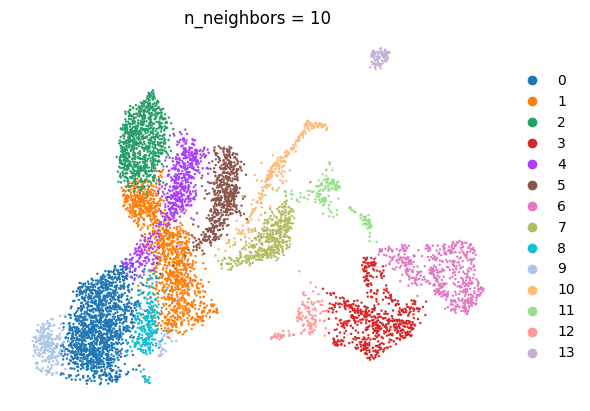

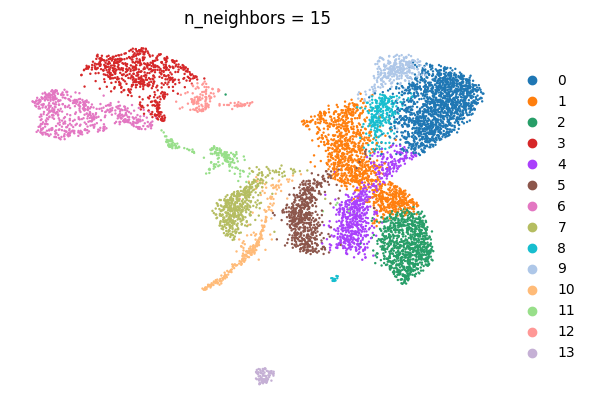

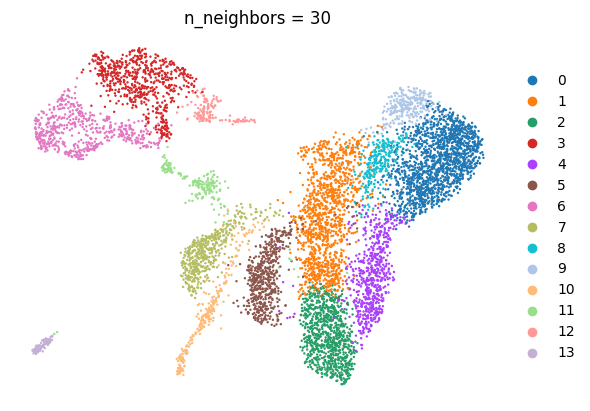

In [41]:
# 클러스터별 UMAP 시각화

# 재현성을 위한 난수 시드 고정
RANDOM_STATE = 0

# k (n_neighbors) 값별로 UMAP을 계산하여 개별 출력
for k in [10, 15, 30]:
    tmp = adata.copy()  # 원본 adata 보호를 위해 복사본 사용
    sc.pp.neighbors(tmp, n_neighbors=k, random_state=RANDOM_STATE)
    sc.tl.umap(tmp, random_state=RANDOM_STATE)
    sc.pl.umap(
        tmp,
        color="leiden",  # 확인하고 싶은 obs 컬럼명
        size=12,
        title=f"n_neighbors = {k}",
        show=True,
        frameon=False
    )

In [45]:
import scanpy as sc
import pandas as pd

# 각 클러스터의 Marker Gene 분석
sc.tl.rank_genes_groups(
    adata,
    groupby='leiden',
    method='t-test',
    use_raw=False,
    pts=True
)

print("Marker Gene Analysis is done")

Marker Gene Analysis is done


In [46]:
# 각 클러스터별 상위 7개 Marker Gene 추출

results = []

for cluster in adata.obs['leiden'].cat.categories:

    df = sc.get.rank_genes_groups_df(
        adata,
        group=cluster
    )

    # 유의한 Marker Gene 선정
    df = df[
        (df['pvals_adj'] < 0.05) &
        (df['logfoldchanges'] > 0.25)
    ]

    top_genes = df['names'].head(7).tolist()

    results.append({
        'Cluster': cluster,
        'Top Marker Genes': ', '.join(top_genes)
    })

marker_summary = pd.DataFrame(results)

display(marker_summary)

,Cluster,Top Marker Genes
0,0,"IFITM2, FCGR3A, LST1, IFITM3, FCER1G, LY6E, AIF1"
1,1,"RPS26, HLA-DRB1, CD52, PRELID1, LGALS2, RPS3A,..."
2,2,"S100A8, S100A9, LYZ, VCAN, RPS26, S100A12, GAPDH"
3,3,"CD74, HLA-DRA, HLA-DRB1, HLA-DPB1, HLA-DMA, IG..."
4,4,"LYZ, RPL39, S100A8, S100A4, S100A9, S100A6, RPL34"
5,5,"FOS, S100A8, LYZ, IER2, S100A9, CEBPD, DUSP1"
6,6,"IER3, CD83, C1QC, C1QA, C1QB, FOSB, NFKBIA"
7,7,"FOS, LYZ, S100A9, S100A8, DUSP1, KLF6, VCAN"
8,8,"IFITM3, IFITM2, LST1, DUSP1, FCGR3A, RHOB, JUNB"
9,9,"FCGR3A, LST1, LINC01272, RPS19, IFITM2, SERPIN..."


In [47]:
import re
bad = re.compile(r'^(RPL|RPS|MT-|IGLV|IGKV|IGHV|IGLC|IGKC|FOS|JUN|DUSP1|IER)')
for c in adata.obs['leiden'].cat.categories:
    g = sc.get.rank_genes_groups_df(adata, group=c)['names']
    print(c, [x for x in g if not bad.match(x)][:7])

0 ['IFITM2', 'FCGR3A', 'LST1', 'IFITM3', 'FCER1G', 'LY6E', 'AIF1']
1 ['HLA-DRB1', 'CD52', 'PRELID1', 'LGALS2', 'LILRB1', 'DDIT4', 'KLF2']
2 ['S100A8', 'S100A9', 'LYZ', 'VCAN', 'S100A12', 'GAPDH', 'S100A6']
3 ['CD74', 'HLA-DRA', 'HLA-DRB1', 'HLA-DPB1', 'HLA-DMA', 'HLA-DQA1', 'HLA-DPA1']
4 ['LYZ', 'S100A8', 'S100A4', 'S100A9', 'S100A6', 'FCN1', 'AC090498.1']
5 ['S100A8', 'LYZ', 'S100A9', 'CEBPD', 'EGR1', 'VCAN', 'S100A4']
6 ['CD83', 'C1QC', 'C1QA', 'C1QB', 'NFKBIA', 'CXCL8', 'PPP1R15A']
7 ['LYZ', 'S100A9', 'S100A8', 'KLF6', 'VCAN', 'MCL1', 'FCN1']
8 ['IFITM3', 'IFITM2', 'LST1', 'FCGR3A', 'RHOB', 'KLF2', 'EGR1']
9 ['FCGR3A', 'LST1', 'LINC01272', 'IFITM2', 'SERPINA1', 'LILRB2', 'CORO1A']
10 ['LYZ', 'RETN', 'S100A8', 'S100A9', 'LINC00936', 'KLF6', 'VCAN']
11 ['CD74', 'HLA-DQA1', 'HLA-DPB1', 'HLA-DQB1', 'HLA-DRA', 'HLA-DPA1', 'HLA-DRB1']
12 ['SOD2', 'IL1B', 'SRGN', 'PPP1R15A', 'NFKBIA', 'PLAUR', 'CDKN1A']
13 ['ITM2C', 'JCHAIN', 'PLD4', 'IRF8', 'ALOX5AP', 'IRF7', 'TCF4']


Mono_CD14 available markers: ['FCN1', 'S100A9', 'S100A8']
Mono_CD16 available markers: ['FCGR3A', 'LST1', 'LILRB2']
Mono/Macro available markers: ['CD68', 'CD163']
Macro_C1QC available markers: ['C1QC', 'C1QA', 'APOE']
Macro_NLRP3 available markers: ['NLRP3', 'EREG', 'IL1B']
cDC1 available markers: ['CLEC9A', 'FLT3', 'IDO1']
cDC2 available markers: ['CD1C', 'FCER1A', 'HLA-DQA1']
cDC3_LAMP3 available markers: ['LAMP3', 'CCR7', 'FSCN1']
pDC available markers: ['LILRA4', 'GZMB', 'IL3RA']
Mast available markers: ['KIT']


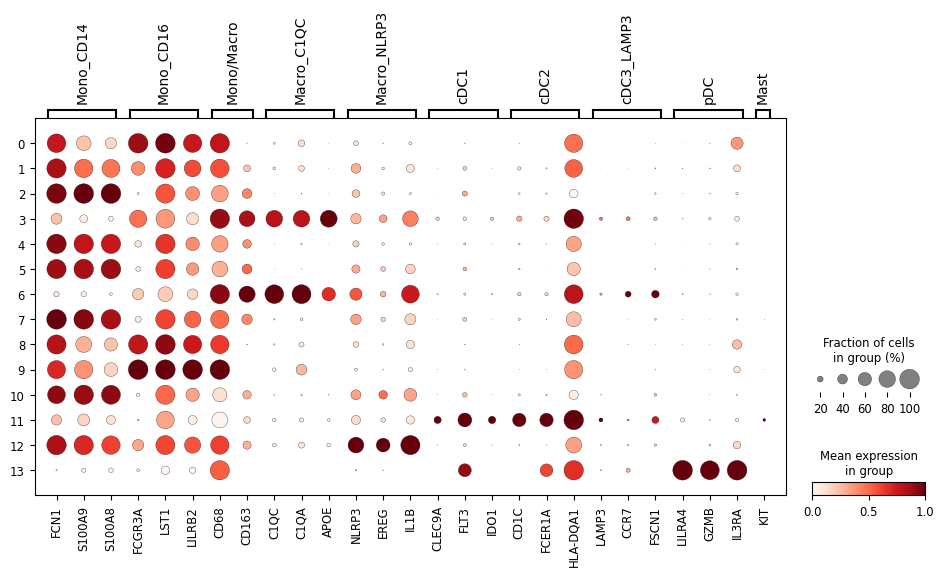

In [51]:
import scanpy as sc

# 세포 유형별 대표 Marker gene
marker_genes = {
    "Mono_CD14":   ["FCN1", "S100A9", "S100A8"],    # Fig 1E
    "Mono_CD16":   ["FCGR3A", "LST1", "LILRB2"],    # Fig 1E
    "Mono/Macro":  ["CD68", "CD163"],               # Fig 1D
    "Macro_C1QC":  ["C1QC", "C1QA", "APOE"],        # Fig 1E
    "Macro_NLRP3": ["NLRP3", "EREG", "IL1B"],       # Fig 1E
    "cDC1":        ["CLEC9A", "FLT3", "IDO1"],      # Fig 1E
    "cDC2":        ["CD1C", "FCER1A", "HLA-DQA1"],  # Fig 1E, Fig 1D
    "cDC3_LAMP3":  ["LAMP3", "CCR7", "FSCN1"],      # Fig 1E
    "pDC":         ["LILRA4", "GZMB", "IL3RA"],     # Fig 1E, Fig 1D
    "Mast":        ["KIT", "TPSAB1", "CPA3"],       # Fig 1E, Fig 1D
}

tam_subsets = {   # 논문 TAM 아형
    "Macro_SPP1":  ["SPP1"],
    "Macro_C1QC":  ["C1QC"],
    "Macro_ISG15": ["ISG15"],
}

# 1. 데이터셋에 존재하는 유전자만 필터링하여 새로운 딕셔너리 생성
available_markers = {}
for cell_type, genes in marker_genes.items():
    available = [gene for gene in genes if gene in adata.var_names]
    if available:
        available_markers[cell_type] = available
        print(f"{cell_type} available markers: {available}")

# 2. 필터링된 딕셔너리를 통째로 전달하여 하나의 통합된 dotplot 생성
sc.pl.dotplot(
    adata,
    var_names=available_markers,
    groupby="leiden",
    standard_scale="var",
    use_raw=False,
    cmap="Reds" # 이미지와 비슷한 파랑-노랑-빨강 색상 맵 적용
)

In [53]:
mast = ['KIT', 'TPSAB1', 'TPSB2', 'CPA3', 'MS4A2', 'HDC']
print('데이터에 있는 마스트 유전자:', [g for g in mast if g in adata.var_names])
print('KIT 발현 세포 수:', (adata[:, 'KIT'].X > 0).sum())

데이터에 있는 마스트 유전자: ['KIT']
KIT 발현 세포 수: 16


In [55]:
import pandas as pd

annot_table = pd.DataFrame([
    ['2, 4, 5, 7, 10', 'Mono_CD14',                     'FCN1, S100A9, S100A8'],
    ['0, 8, 9',        'Mono_CD16',                     'FCGR3A, LST1, LILRB2'],
    ['1',              'Mono_CD14CD16 (중간형)',         'CD14·CD16 마커 둘 다 중간'],
    ['6',              'Macro_C1QC',                    'C1QC, C1QA, CD163'],
    ['3',              'Macro_C1QC (APOE 높은 쪽)',      'APOE, CD68, CD163, HLA-DQA1'],
    ['12',             'Macro_NLRP3',                   'NLRP3, EREG, IL1B'],
    ['11',             'cDC (cDC2 위주, cDC1 일부)',     'CD1C, FCER1A, HLA-DQA1'],
    ['13',             'pDC',                           'LILRA4, GZMB, IL3RA'],
    ['-',              'Mast (없음)',                    'KIT 거의 0'],
], columns=['클러스터', '세포 유형', '가장 진한 마커'])

# 클러스터별 세포 수 합치기
counts = adata.obs['leiden'].value_counts()
annot_table['세포 수'] = annot_table['클러스터'].apply(
    lambda s: sum(counts.get(c.strip(), 0) for c in s.split(',')))

annot_table

,클러스터,세포 유형,가장 진한 마커,세포 수
0,"2, 4, 5, 7, 10",Mono_CD14,"FCN1, S100A9, S100A8",2773
1,"0, 8, 9",Mono_CD16,"FCGR3A, LST1, LILRB2",2081
2,1,Mono_CD14CD16 (중간형),CD14·CD16 마커 둘 다 중간,1188
3,6,Macro_C1QC,"C1QC, C1QA, CD163",545
4,3,Macro_C1QC (APOE 높은 쪽),"APOE, CD68, CD163, HLA-DQA1",640
5,12,Macro_NLRP3,"NLRP3, EREG, IL1B",135
6,11,"cDC (cDC2 위주, cDC1 일부)","CD1C, FCER1A, HLA-DQA1",175
7,13,pDC,"LILRA4, GZMB, IL3RA",82
8,-,Mast (없음),KIT 거의 0,0
